# Событийная аналитика интернет-магазина: валидация данных, воронка, витрины и дашборд на SQL

**Цель:** на логе пользовательских событий интернет-магазина пройти типичный путь продуктового аналитика: проверить качество данных, построить воронку `просмотр → добавление в корзину → покупка`, собрать витрины данных, оптимизировать запросы и сделать дашборд с фильтрами.

**Данные:** [Retailrocket recommender system dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset) (файл `events.csv`): реальный лог событий интернет-магазина за ~4,5 месяца 2015 года, около 2,75 млн событий и 1,4 млн посетителей.

| Колонка | Описание |
|---|---|
| `timestamp` | время события, Unix-время в миллисекундах (UTC) |
| `visitorid` | идентификатор посетителя |
| `event` | тип события: `view`, `addtocart`, `transaction` |
| `itemid` | идентификатор товара |
| `transactionid` | идентификатор заказа (заполнен только для `transaction`) |

**Технологии:** Python (pandas, matplotlib, ipywidgets) и **SQL (SQLite)**: вся логика проверок, воронок и витрин написана на SQL, Python используется для запуска запросов и визуализации.

**План ноутбука:**
0. Постановка задачи и метрики
1. План логирования событий (tracking plan)
2. Загрузка данных
3. Валидация данных: полнота, корректность, дубли, логика, боты
4. Витрины данных: сессии, пользователи, дни
5. Воронка пользовательских действий
6. Эд-хок запросы
7. Рефакторинг и оптимизация SQL (до / после)
8. Дашборд с фильтрами
9. Итоги

## Шаг 0. Постановка задачи

**Бизнес-вопросы:**
1. Можно ли доверять событийным данным и что нужно исправить до анализа?
2. На каком шаге воронки теряется больше всего пользователей?
3. Как конверсия меняется во времени и в разрезе дня недели и времени суток?
4. Как быстро пользователи проходят шаги воронки и какие товары чаще «застревают» в корзине?

**Определения метрик (зафиксированы заранее):**

| Метрика | Определение |
|---|---|
| Сессия | последовательность событий одного посетителя с паузой между соседними событиями не более 30 минут |
| Воронка пользователей | шаг 1: был `view`; шаг 2: после первого `view` было `addtocart`; шаг 3: после первого `addtocart` была `transaction` |
| Конверсия шага | доля пользователей, дошедших до шага, от предыдущего шага |
| Конверсия в покупку | пользователи на шаге 3 / пользователи на шаге 1 |
| Отказ от корзины | доля пользователей, добавивших товар в корзину, но не купивших после этого |

Порядок шагов важен: покупка до добавления в корзину в строгую воронку не входит, но такие случаи считаются отдельно, потому что они говорят о пробелах в логировании.

## Шаг 1. План логирования событий (tracking plan)

Прежде чем проверять данные, нужно определить, **какими они должны быть**. Ниже спецификация событий, на которую опираются проверки качества в шаге 3.

| Событие | Когда отправляется | Обязательные поля | Правила валидации |
|---|---|---|---|
| `view` | пользователь открыл карточку товара | `timestamp`, `visitorid`, `itemid` | `transactionid` пустой; одно событие на открытие страницы, без повторов в пределах секунды |
| `addtocart` | пользователь добавил товар в корзину | `timestamp`, `visitorid`, `itemid` | `transactionid` пустой; обычно после `view` того же товара |
| `transaction` | заказ оформлен | `timestamp`, `visitorid`, `itemid`, `transactionid` | `transactionid` заполнен и уникален для заказа; один заказ принадлежит одному посетителю |

**Общие правила:** `event` только из трёх допустимых значений; `timestamp` в разумных границах периода сбора; пара (`timestamp`, `visitorid`, `event`, `itemid`) не повторяется.

**Чего не хватает в этом датасете и что стоило бы логировать в реальном продукте:** `session_id` (приходится восстанавливать по паузам), платформа и источник трафика, цена и количество в `transaction`, событие `checkout_started` (между корзиной и покупкой нет промежуточных шагов), признак авторизации пользователя.

## Шаг 2. Загрузка данных

Сырые события загружаются в таблицу `events_raw` базы SQLite «как есть», без очистки. Все дальнейшие шаги выполняются SQL-запросами над этой базой.

In [2]:
import time
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

# ---- Параметры анализа ----
SEED = 42
SESSION_GAP_MIN = 30             # пауза (мин), после которой начинается новая сессия
WINDOW_START, WINDOW_END = "2015-05-01", "2015-10-01"   # ожидаемый период сбора данных (end не включается)
BOT_MIN_EVENTS = 500             # посетители с таким числом событий и без покупок считаем ботами
NEAR_DUP_MS = 1_000              # «быстрый повтор» события: меньше 1 секунды
LOW_DAY_SHARE = 0.5              # день считается просевшим, если событий меньше 50% медианы
MIN_CARTS_ITEM = 20              # минимум добавлений в корзину для разбора товара
OPT_DAYS = 3                     # сколько дней берём для сравнения «до / после» в оптимизации

EVENTS = ("view", "addtocart", "transaction")

In [3]:
CSV_CANDIDATES = [Path("../data/events.csv"), Path("data/events.csv"), Path("events.csv")]
csv_path = next((p for p in CSV_CANDIDATES if p.exists()), None)
USING_SYNTHETIC = csv_path is None

DATA_DIR = next((p.parent for p in CSV_CANDIDATES if p.parent.exists()), Path("data"))
DATA_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = DATA_DIR / "analytics.db"
DB_PATH.unlink(missing_ok=True)          # база пересобирается при каждом запуске

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA journal_mode=OFF")
conn.execute("PRAGMA synchronous=OFF")
conn.execute("PRAGMA cache_size=-400000")
print("SQLite", sqlite3.sqlite_version)


def q(sql, params=()):
    """Выполнить SELECT и вернуть DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)


def run(sql):
    """Выполнить DDL/DML (CREATE, INSERT, ...)."""
    conn.execute(sql)
    conn.commit()


def timed(fn, repeat=1):
    """Минимальное время выполнения функции за repeat запусков."""
    best, res = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter()
        res = fn()
        best = min(best, time.perf_counter() - t0)
    return res, best

SQLite 3.50.4


In [4]:
def make_synthetic(seed=SEED, n_visitors=150_000):
    """Синтетический лог той же структуры, что и Retailrocket events.csv, с намеренно внесёнными дефектами.
    Нужен только чтобы ноутбук запускался без файла. Выводы по нему не имеют отношения к реальному магазину."""
    g = np.random.default_rng(seed)
    start = int(pd.Timestamp("2015-05-03").value // 10**6)
    days = 130
    vid = g.choice(np.arange(1, 5_000_000), size=n_visitors, replace=False)
    n_views = g.geometric(0.55, size=n_visitors)
    heavy = g.random(n_visitors) < 0.01
    n_views[heavy] += g.integers(5, 60, size=heavy.sum())
    first_t = start + (g.random(n_visitors) * days * 86_400_000).astype(np.int64)

    idx = np.repeat(np.arange(n_visitors), n_views)
    first_pos = np.cumsum(n_views) - n_views
    pos = np.arange(len(idx)) - np.repeat(first_pos, n_views)
    gaps = g.exponential(3 * 60_000, size=len(idx))
    gaps[g.random(len(idx)) < 0.08] += 3 * 3_600_000
    gaps[pos == 0] = 0
    cs = np.cumsum(gaps)
    t_view = first_t[idx] + (cs - np.repeat(cs[first_pos], n_views)).astype(np.int64)
    items = np.minimum(g.lognormal(6.5, 1.4, size=len(idx)).astype(int), 3000) + 1000
    views = pd.DataFrame({"timestamp": t_view, "visitorid": vid[idx], "event": "view", "itemid": items, "transactionid": np.nan})

    last = np.cumsum(n_views) - 1
    cart_mask = g.random(n_visitors) < np.where(heavy, 0.12, 0.03)
    c_idx = np.where(cart_mask)[0]
    t_cart = t_view[last[c_idx]] + g.exponential(4 * 60_000, size=len(c_idx)).astype(np.int64) + 1_000
    carts = pd.DataFrame({"timestamp": t_cart, "visitorid": vid[c_idx], "event": "addtocart", "itemid": items[last[c_idx]], "transactionid": np.nan})

    buy_mask = g.random(len(c_idx)) < 0.30
    direct = np.where(~cart_mask & (g.random(n_visitors) < 0.0015))[0]
    b_vid = np.concatenate([vid[c_idx][buy_mask], vid[direct]])
    b_t = np.concatenate([t_cart[buy_mask] + g.exponential(20 * 60_000, size=buy_mask.sum()).astype(np.int64) + 1_000,
                          t_view[last[direct]] + g.exponential(10 * 60_000, size=len(direct)).astype(np.int64) + 1_000])
    b_item = np.concatenate([items[last[c_idx]][buy_mask], items[last[direct]]])
    tid = np.arange(1, len(b_vid) + 1)
    buys = pd.DataFrame({"timestamp": b_t, "visitorid": b_vid, "event": "transaction", "itemid": b_item, "transactionid": tid.astype(float)})
    second = buys.sample(frac=0.15, random_state=seed).copy()
    second["itemid"] = second["itemid"] + 1
    second["timestamp"] += 1_000
    buys = pd.concat([buys, second])

    df = pd.concat([views, carts, buys], ignore_index=True)

    # --- намеренно внесённые дефекты ---
    d = df.sample(frac=0.004, random_state=seed + 1)
    df = pd.concat([df, d], ignore_index=True)                                     # точные дубли
    tr = df.index[df["event"] == "transaction"]
    df.loc[g.choice(tr, size=max(1, int(len(tr) * 0.003)), replace=False), "transactionid"] = np.nan   # покупка без id заказа
    vw = df.index[df["event"] == "view"]
    df.loc[g.choice(vw, size=40, replace=False), "transactionid"] = 999_999.0       # id заказа у просмотра
    df.loc[g.choice(vw, size=25, replace=False), "event"] = "click"                 # недопустимый тип события
    df.loc[g.choice(vw, size=15, replace=False), "timestamp"] = g.integers(0, 86_400_000, size=15)   # 1970 год
    day60 = start + 60 * 86_400_000
    drop = df.index[(df["timestamp"] >= day60) & (df["timestamp"] < day60 + 86_400_000)]
    df = df.drop(g.choice(drop, size=int(len(drop) * 0.85), replace=False))         # «авария» логирования в один из дней
    bots = []
    for b in range(12):                                                              # боты
        n = 4000
        bots.append(pd.DataFrame({"timestamp": start + 20 * 86_400_000 + np.sort(g.integers(0, 2 * 86_400_000, size=n)),
                                  "visitorid": 20_000_000 + b, "event": "view",
                                  "itemid": g.integers(1000, 4000, size=n), "transactionid": np.nan}))
    df = pd.concat([df] + bots, ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


COLS = {"timestamp": "ts_ms", "visitorid": "visitor_id", "event": "event", "itemid": "item_id", "transactionid": "transaction_id"}


def prepare(chunk):
    chunk = chunk.rename(columns=COLS)
    chunk["ts_ms"] = pd.to_numeric(chunk["ts_ms"], errors="coerce").astype("Int64")
    dt = pd.to_datetime(chunk["ts_ms"].astype("float64"), unit="ms", errors="coerce")
    chunk["event_dt"] = dt.dt.strftime("%Y-%m-%d %H:%M:%S")
    chunk["event_date"] = chunk["event_dt"].str[:10]
    chunk["visitor_id"] = chunk["visitor_id"].astype("Int64")
    chunk["item_id"] = chunk["item_id"].astype("Int64")
    chunk["transaction_id"] = chunk["transaction_id"].astype("Int64")
    return chunk[["ts_ms", "visitor_id", "event", "item_id", "transaction_id", "event_dt", "event_date"]]


t0 = time.perf_counter()
if USING_SYNTHETIC:
    print("⚠️ events.csv не найден. Используются СИНТЕТИЧЕСКИЕ данные для проверки работы ноутбука.")
    print("   Скачай датасет с Kaggle (retailrocket/ecommerce-dataset) и положи events.csv в папку data/.")
    prepare(make_synthetic()).to_sql("events_raw", conn, index=False, if_exists="replace")
else:
    print(f"Загрузка {csv_path} ...")
    for i, chunk in enumerate(pd.read_csv(csv_path, chunksize=500_000)):
        prepare(chunk).to_sql("events_raw", conn, index=False, if_exists="append")
print(f"events_raw загружена за {time.perf_counter() - t0:.1f} с")
q("SELECT * FROM events_raw LIMIT 5")

Загрузка data\events.csv ...
events_raw загружена за 4.0 с


,ts_ms,visitor_id,event,item_id,transaction_id,event_dt,event_date
0,1433221332117,257597,view,355908,None,2015-06-02 05:02:12,2015-06-02
1,1433224214164,992329,view,248676,None,2015-06-02 05:50:14,2015-06-02
2,1433221999827,111016,view,318965,None,2015-06-02 05:13:19,2015-06-02
3,1433221955914,483717,view,253185,None,2015-06-02 05:12:35,2015-06-02
4,1433221337106,951259,view,367447,None,2015-06-02 05:02:17,2015-06-02


In [5]:
overview = q("""
SELECT COUNT(*)                          AS rows_total,
       COUNT(DISTINCT visitor_id)        AS visitors,
       COUNT(DISTINCT item_id)           AS items,
       MIN(event_date)                   AS first_date,
       MAX(event_date)                   AS last_date
FROM events_raw
""")
display(overview)
q("""
SELECT event, COUNT(*) AS events, ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM events_raw), 3) AS share_pct
FROM events_raw GROUP BY event ORDER BY events DESC
""")

,rows_total,visitors,items,first_date,last_date
0,2756101,1407580,235061,2015-05-03,2015-09-18


,event,events,share_pct
0,view,2664312,96.6700
1,addtocart,69332,2.5160
2,transaction,22457,0.8150


## Шаг 3. Валидация данных

Каждая проверка записывается в сводную таблицу качества данных (`quality_report`) с указанием того, **что сделано с проблемой**: удалено, исправлено или оставлено с пометкой.

In [6]:
quality = []
N_RAW = int(overview.loc[0, "rows_total"])


def add_check(group, name, bad, action):
    quality.append({"Группа": group, "Проверка": name, "Затронуто строк": int(bad),
                    "Доля, %": 100 * int(bad) / N_RAW, "Что сделано": action})

### 3.1 Полнота: пропуски в ключевых полях

Для `transaction` поле `transactionid` обязательно, для остальных событий должно быть пустым (см. tracking plan).

In [7]:
completeness = q("""
SELECT event,
       COUNT(*)                                    AS n,
       SUM(ts_ms IS NULL)                          AS null_ts,
       SUM(visitor_id IS NULL)                     AS null_visitor,
       SUM(item_id IS NULL)                        AS null_item,
       SUM(transaction_id IS NULL)                 AS null_transaction_id
FROM events_raw
GROUP BY event
""")
display(completeness)

null_keys = q("SELECT COUNT(*) AS n FROM events_raw WHERE ts_ms IS NULL OR visitor_id IS NULL OR item_id IS NULL").iloc[0, 0]
tr_no_id = q("SELECT COUNT(*) FROM events_raw WHERE event = 'transaction' AND transaction_id IS NULL").iloc[0, 0]
other_with_id = q("SELECT COUNT(*) FROM events_raw WHERE event IN ('view','addtocart') AND transaction_id IS NOT NULL").iloc[0, 0]

add_check("Полнота", "Пропуск в ts / visitor / item", null_keys, "удалено")
add_check("Полнота", "transaction без transactionid", tr_no_id, "оставлено, помечено (покупка реальна, но заказ не идентифицирован)")
add_check("Корректность", "view/addtocart с transactionid", other_with_id, "оставлено, transactionid обнулён")
print(f"Пропуски в ключевых полях: {null_keys}; покупок без transactionid: {tr_no_id}; просмотров/корзин с transactionid: {other_with_id}")

,event,n,null_ts,null_visitor,null_item,null_transaction_id
0,addtocart,69332,0,0,0,69332
1,transaction,22457,0,0,0,0
2,view,2664312,0,0,0,2664312


Пропуски в ключевых полях: 0; покупок без transactionid: 0; просмотров/корзин с transactionid: 0


### 3.2 Корректность: допустимые типы событий и временные границы

In [8]:
types = q("""
SELECT event, COUNT(*) AS n,
       CASE WHEN event IN ('view','addtocart','transaction') THEN 'допустимо' ELSE 'НЕДОПУСТИМО' END AS status
FROM events_raw GROUP BY event ORDER BY n DESC
""")
display(types)
bad_types = q("SELECT COUNT(*) FROM events_raw WHERE event NOT IN ('view','addtocart','transaction') OR event IS NULL").iloc[0, 0]
add_check("Корректность", "Недопустимый тип события", bad_types, "удалено")

bad_time = q(f"""
SELECT COUNT(*) FROM events_raw
WHERE event_date IS NULL OR event_date < '{WINDOW_START}' OR event_date >= '{WINDOW_END}'
""").iloc[0, 0]
add_check("Корректность", f"Время вне периода [{WINDOW_START}; {WINDOW_END})", bad_time, "удалено")
display(q(f"""
SELECT event_date, COUNT(*) AS n FROM events_raw
WHERE event_date IS NULL OR event_date < '{WINDOW_START}' OR event_date >= '{WINDOW_END}'
GROUP BY event_date ORDER BY n DESC LIMIT 10
"""))

,event,n,status
0,view,2664312,допустимо
1,addtocart,69332,допустимо
2,transaction,22457,допустимо


,event_date,n


### 3.3 Дубли

Точный дубль: совпадают все поля события. Лишними считаются все строки сверх первой в группе одинаковых.

In [9]:
dups = q("""
SELECT COALESCE(SUM(cnt - 1), 0) AS excess_rows, COUNT(*) AS duplicated_groups, COALESCE(MAX(cnt), 0) AS max_repeat
FROM (SELECT COUNT(*) AS cnt FROM events_raw
      GROUP BY ts_ms, visitor_id, event, item_id, transaction_id HAVING COUNT(*) > 1)
""")
display(dups)
add_check("Дубли", "Точные дубли событий (лишние строки)", dups.loc[0, "excess_rows"], "удалено (оставлено по одной строке)")

tr_multi_visitor = q("""
SELECT COUNT(*) FROM (SELECT transaction_id FROM events_raw WHERE transaction_id IS NOT NULL AND event = 'transaction'
                      GROUP BY transaction_id HAVING COUNT(DISTINCT visitor_id) > 1)
""").iloc[0, 0]
print(f"Заказов (transactionid), привязанных больше чем к одному посетителю: {tr_multi_visitor}")

,excess_rows,duplicated_groups,max_repeat
0,460,458,3


Заказов (transactionid), привязанных больше чем к одному посетителю: 0


### 3.4 Очистка: слой `events_clean`

Из сырой таблицы удаляем недопустимые типы, пропуски в ключевых полях, время вне периода и точные дубли. Нетипичное `transactionid` у `view` и `addtocart` обнуляем.

In [10]:
t0 = time.perf_counter()
run("DROP TABLE IF EXISTS events_clean")
run(f"""
CREATE TABLE events_clean AS
SELECT DISTINCT ts_ms, visitor_id, event, item_id,
       CASE WHEN event = 'transaction' THEN transaction_id END AS transaction_id,
       event_dt, event_date
FROM events_raw
WHERE event IN ('view', 'addtocart', 'transaction')
  AND ts_ms IS NOT NULL AND visitor_id IS NOT NULL AND item_id IS NOT NULL
  AND event_date >= '{WINDOW_START}' AND event_date < '{WINDOW_END}'
""")
n_clean = q("SELECT COUNT(*) FROM events_clean").iloc[0, 0]
print(f"events_clean: {n_clean:,} строк из {N_RAW:,} ({100 * (N_RAW - n_clean) / N_RAW:.2f}% удалено) за {time.perf_counter() - t0:.1f} с")

events_clean: 2,755,641 строк из 2,756,101 (0.02% удалено) за 2.2 с


### 3.5 Динамика по дням: пропуски и провалы логирования

Просевший день (событий меньше `LOW_DAY_SHARE` от медианы) часто означает сбой логирования, а не реальное падение трафика. Первый и последний день периода обычно неполные, их отмечаем отдельно.

Медиана событий в день: 20,619. Просевших дней: 2


,date,events,edge_day
137,2015-09-17,10126,False
138,2015-09-18,1528,True


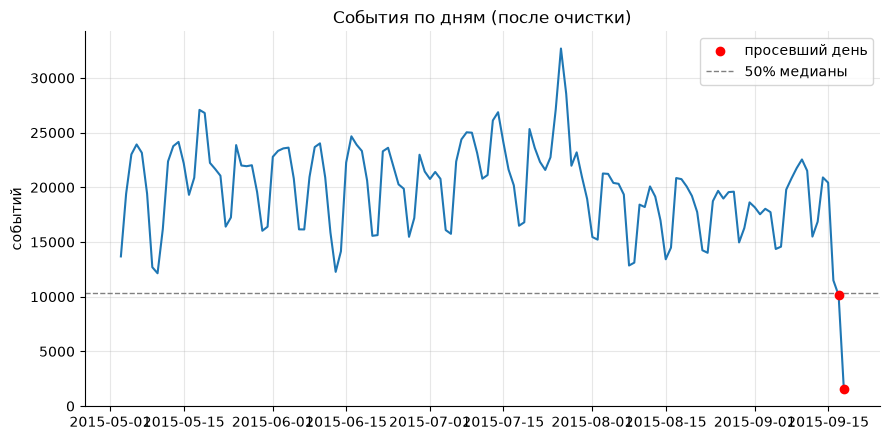

In [11]:
daily_raw = q("""
WITH RECURSIVE cal(d) AS (
    SELECT MIN(event_date) FROM events_clean
    UNION ALL
    SELECT date(d, '+1 day') FROM cal WHERE d < (SELECT MAX(event_date) FROM events_clean)
)
SELECT cal.d AS date, COALESCE(x.n, 0) AS events
FROM cal LEFT JOIN (SELECT event_date, COUNT(*) AS n FROM events_clean GROUP BY event_date) x ON x.event_date = cal.d
ORDER BY cal.d
""")
daily_raw["date"] = pd.to_datetime(daily_raw["date"])
med = daily_raw["events"].median()
daily_raw["low"] = daily_raw["events"] < LOW_DAY_SHARE * med
flagged = daily_raw[daily_raw["low"]].assign(edge_day=lambda d: d.index.isin([0, len(daily_raw) - 1]))
print(f"Медиана событий в день: {med:,.0f}. Просевших дней: {len(flagged)}")
display(flagged[["date", "events", "edge_day"]])

fig, ax = plt.subplots()
ax.plot(daily_raw["date"], daily_raw["events"], lw=1.5)
ax.scatter(flagged["date"], flagged["events"], color="red", zorder=3, label="просевший день")
ax.axhline(LOW_DAY_SHARE * med, color="gray", ls="--", lw=1, label=f"{int(LOW_DAY_SHARE * 100)}% медианы")
ax.set_title("События по дням (после очистки)"); ax.set_ylabel("событий"); ax.legend()
plt.tight_layout(); plt.show()

inner_low = flagged[~flagged["edge_day"]]
add_check("Динамика", "События в просевшие внутренние дни (не крайние)", inner_low["events"].sum(), "оставлено, дни отмечены; учитывать при анализе трендов")

### 3.6 Боты и аномальная активность

Посетители с аномально большим числом событий искажают метрики активности и просмотров. Посмотрим на распределение и зададим порог.

Квантили числа событий на посетителя:
0.5000       1.0000
0.9000       3.0000
0.9900      13.0000
0.9990      47.0000
0.9999     280.2105
1.0000   7,757.0000

Топ-10 самых активных посетителей:


,visitor_id,n,purchases,active_days
1150086,1150086,7757,559,74
530559,530559,4328,286,73
152963,152963,3024,349,38
895999,895999,2474,50,97
163561,163561,2410,92,21
371606,371606,2345,94,18
286616,286616,2252,75,19
684514,684514,2246,189,18
892013,892013,2024,0,42
861299,861299,1991,188,21



Посетителей с ≥ 500 событий: 75, из них с покупками (оставляем): 60


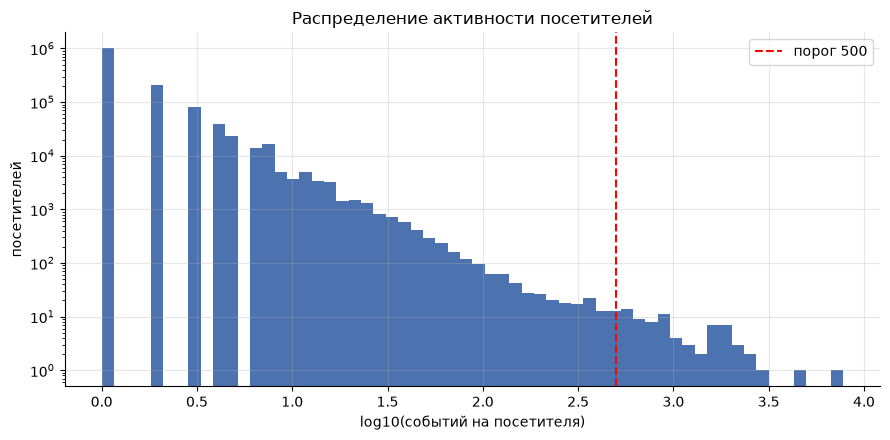

In [12]:
per_visitor = q("""
SELECT visitor_id, COUNT(*) AS n, SUM(event = 'transaction') AS purchases, COUNT(DISTINCT event_date) AS active_days
FROM events_clean GROUP BY visitor_id
""")
print("Квантили числа событий на посетителя:")
print(per_visitor["n"].quantile([.5, .9, .99, .999, .9999, 1]).to_string())
print("\nТоп-10 самых активных посетителей:")
display(per_visitor.nlargest(10, "n"))

heavy = per_visitor[per_visitor["n"] >= BOT_MIN_EVENTS]
print(f"\nПосетителей с ≥ {BOT_MIN_EVENTS} событий: {len(heavy)}, из них с покупками (оставляем): {(heavy['purchases'] > 0).sum()}")

fig, ax = plt.subplots()
ax.hist(np.log10(per_visitor["n"]), bins=60, color="#4C72B0")
ax.axvline(np.log10(BOT_MIN_EVENTS), color="red", ls="--", label=f"порог {BOT_MIN_EVENTS}")
ax.set_xlabel("log10(событий на посетителя)"); ax.set_ylabel("посетителей"); ax.set_yscale("log")
ax.set_title("Распределение активности посетителей"); ax.legend()
plt.tight_layout(); plt.show()

In [13]:
run("DROP TABLE IF EXISTS bots")
run(f"""
CREATE TABLE bots AS
SELECT visitor_id, COUNT(*) AS events, COUNT(DISTINCT event_date) AS active_days
FROM events_clean GROUP BY visitor_id
HAVING COUNT(*) >= {BOT_MIN_EVENTS} AND SUM(event = 'transaction') = 0
""")
bot_events = q("SELECT COUNT(*) FROM events_clean WHERE visitor_id IN (SELECT visitor_id FROM bots)").iloc[0, 0]
n_bots = q("SELECT COUNT(*) FROM bots").iloc[0, 0]
add_check("Боты", f"События посетителей с ≥{BOT_MIN_EVENTS} событий и без покупок", bot_events, "удалено")
print(f"Ботов: {n_bots}, их событий: {bot_events:,} ({100 * bot_events / n_clean:.2f}% от events_clean)")

# Финальный аналитический слой
run("DROP TABLE IF EXISTS events")
run("""
CREATE TABLE events AS
SELECT * FROM events_clean WHERE visitor_id NOT IN (SELECT visitor_id FROM bots)
""")
run("CREATE INDEX idx_events_visitor_ts ON events(visitor_id, ts_ms)")
n_events = q("SELECT COUNT(*) FROM events").iloc[0, 0]
print(f"events (аналитический слой): {n_events:,} строк")

Ботов: 15, их событий: 14,308 (0.52% от events_clean)
events (аналитический слой): 2,741,333 строк


### 3.7 Логическая согласованность

В нормальном сценарии покупке предшествует добавление этого товара в корзину, а корзине предшествует просмотр. Нарушения указывают на пробелы в логировании (покупка в один клик, смена устройства, потерянные события) и влияют на то, как читать воронку.

In [14]:
logic = q("""
SELECT
  (SELECT COUNT(*) FROM events WHERE event = 'transaction') AS purchases,
  (SELECT COUNT(*) FROM events t WHERE t.event = 'transaction' AND NOT EXISTS (
       SELECT 1 FROM events c WHERE c.visitor_id = t.visitor_id AND c.item_id = t.item_id
         AND c.event = 'addtocart' AND c.ts_ms <= t.ts_ms)) AS purchases_without_cart,
  (SELECT COUNT(*) FROM events WHERE event = 'addtocart') AS carts,
  (SELECT COUNT(*) FROM events a WHERE a.event = 'addtocart' AND NOT EXISTS (
       SELECT 1 FROM events v WHERE v.visitor_id = a.visitor_id AND v.item_id = a.item_id
         AND v.event = 'view' AND v.ts_ms <= a.ts_ms)) AS carts_without_view
""")
display(logic)
pwc, pur = logic.loc[0, "purchases_without_cart"], logic.loc[0, "purchases"]
cwv, car = logic.loc[0, "carts_without_view"], logic.loc[0, "carts"]
print(f"Покупок без предшествующего добавления в корзину: {pwc:,} из {pur:,} ({100 * pwc / max(pur, 1):.1f}%)")
print(f"Добавлений в корзину без предшествующего просмотра: {cwv:,} из {car:,} ({100 * cwv / max(car, 1):.1f}%)")
add_check("Логика", "Покупка без добавления этого товара в корзину", pwc, "оставлено; учитывается в воронке отдельной строкой")
add_check("Логика", "Корзина без просмотра этого товара", cwv, "оставлено; пробел логирования или переход по прямой ссылке")

near = q(f"""
SELECT COUNT(*) FROM (
  SELECT ts_ms - LAG(ts_ms) OVER (PARTITION BY visitor_id, item_id, event ORDER BY ts_ms) AS gap
  FROM events
) WHERE gap IS NOT NULL AND gap < {NEAR_DUP_MS}
""").iloc[0, 0]
add_check("Дубли", f"Быстрые повторы (тот же пользователь, товар, событие, < {NEAR_DUP_MS // 1000} с)", near, "оставлено, информационно (возможны двойные клики или перезагрузки)")

,purchases,purchases_without_cart,carts,carts_without_view
0,22457,2452,68946,18881


Покупок без предшествующего добавления в корзину: 2,452 из 22,457 (10.9%)
Добавлений в корзину без предшествующего просмотра: 18,881 из 68,946 (27.4%)


In [15]:
quality_report = pd.DataFrame(quality)
quality_report["Доля, %"] = quality_report["Доля, %"].round(3)
quality_report

,Группа,Проверка,Затронуто строк,"Доля, %",Что сделано
0,Полнота,Пропуск в ts / visitor / item,0,0.0000,удалено
1,Полнота,transaction без transactionid,0,0.0000,"оставлено, помечено (покупка реальна, но заказ..."
2,Корректность,view/addtocart с transactionid,0,0.0000,"оставлено, transactionid обнулён"
3,Корректность,Недопустимый тип события,0,0.0000,удалено
4,Корректность,Время вне периода [2015-05-01; 2015-10-01),0,0.0000,удалено
5,Дубли,Точные дубли событий (лишние строки),460,0.0170,удалено (оставлено по одной строке)
6,Динамика,События в просевшие внутренние дни (не крайние),10126,0.3670,"оставлено, дни отмечены; учитывать при анализе..."
7,Боты,События посетителей с ≥500 событий и без покупок,14308,0.5190,удалено
8,Логика,Покупка без добавления этого товара в корзину,2452,0.0890,оставлено; учитывается в воронке отдельной стр...
9,Логика,Корзина без просмотра этого товара,18881,0.6850,оставлено; пробел логирования или переход по п...


**Итог валидации.** Сводная таблица выше показывает масштаб каждой проблемы и принятое решение. Критичные дефекты (недопустимые события, время вне периода, точные дубли, боты) удалены; дефекты, которые отражают реальные пробелы логирования (покупки без корзины, корзины без просмотра), оставлены и учтены при построении воронки.

## Шаг 4. Витрины данных

Строим три витрины разной детализации. Они нужны, чтобы не пересчитывать тяжёлые запросы по сырым событиям каждый раз:

| Витрина | Гранулярность | Для чего |
|---|---|---|
| `mart_session` | сессия | воронка по сессиям, время суток и день недели |
| `mart_user` | пользователь | воронка по пользователям, когорты, время между шагами |
| `mart_daily` | день | тренды, дашборд |

Сначала восстанавливаем сессии: новая сессия начинается, если пауза с предыдущим событием посетителя превышает `SESSION_GAP_MIN` минут.

In [16]:
t0 = time.perf_counter()
run("DROP TABLE IF EXISTS events_sess")
run(f"""
CREATE TABLE events_sess AS
WITH s AS (
    SELECT rowid AS rid, *,
           CASE WHEN LAG(ts_ms) OVER (PARTITION BY visitor_id ORDER BY ts_ms, rowid) IS NULL
                  OR ts_ms - LAG(ts_ms) OVER (PARTITION BY visitor_id ORDER BY ts_ms, rowid) > {SESSION_GAP_MIN} * 60 * 1000
                THEN 1 ELSE 0 END AS is_new_session
    FROM events
)
SELECT ts_ms, visitor_id, event, item_id, transaction_id, event_dt, event_date,
       SUM(is_new_session) OVER (PARTITION BY visitor_id ORDER BY ts_ms, rid
                                 ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS session_no
FROM s
""")
print(f"events_sess построена за {time.perf_counter() - t0:.1f} с")
q("SELECT * FROM events_sess ORDER BY visitor_id, ts_ms LIMIT 8")

events_sess построена за 7.5 с


,ts_ms,visitor_id,event,item_id,transaction_id,event_dt,event_date,session_no
0,1442004589439,0,view,285930,None,2015-09-11 20:49:49,2015-09-11,1
1,1442004759591,0,view,357564,None,2015-09-11 20:52:39,2015-09-11,1
2,1442004917175,0,view,67045,None,2015-09-11 20:55:17,2015-09-11,1
3,1439487966444,1,view,72028,None,2015-08-13 17:46:06,2015-08-13,1
4,1438969904567,2,view,325215,None,2015-08-07 17:51:44,2015-08-07,1
5,1438970013790,2,view,325215,None,2015-08-07 17:53:33,2015-08-07,1
6,1438970212664,2,view,259884,None,2015-08-07 17:56:52,2015-08-07,1
7,1438970468920,2,view,216305,None,2015-08-07 18:01:08,2015-08-07,1


In [17]:
t0 = time.perf_counter()
run("DROP TABLE IF EXISTS mart_session")
run("""
CREATE TABLE mart_session AS
SELECT visitor_id, session_no,
       MIN(ts_ms)                 AS start_ts,
       MAX(ts_ms)                 AS end_ts,
       MIN(event_date)            AS start_date,
       COUNT(*)                   AS events,
       SUM(event = 'view')        AS views,
       SUM(event = 'addtocart')   AS carts,
       SUM(event = 'transaction') AS purchases
FROM events_sess
GROUP BY visitor_id, session_no
""")

run("DROP TABLE IF EXISTS mart_user")
run("""
CREATE TABLE mart_user AS
SELECT visitor_id,
       MIN(ts_ms)                                             AS first_ts,
       MAX(ts_ms)                                             AS last_ts,
       MIN(event_date)                                        AS first_date,
       COUNT(DISTINCT event_date)                             AS active_days,
       MAX(session_no)                                        AS sessions,
       SUM(event = 'view')                                    AS views,
       SUM(event = 'addtocart')                               AS carts,
       SUM(event = 'transaction')                             AS purchases,
       COUNT(DISTINCT CASE WHEN event = 'transaction' THEN transaction_id END) AS orders,
       MIN(CASE WHEN event = 'view'        THEN ts_ms END)    AS t_view,
       MIN(CASE WHEN event = 'addtocart'   THEN ts_ms END)    AS t_cart,
       MIN(CASE WHEN event = 'transaction' THEN ts_ms END)    AS t_buy,
       MIN(CASE WHEN event = 'view'        THEN event_date END) AS d_view
FROM events_sess
GROUP BY visitor_id
""")

run("DROP TABLE IF EXISTS mart_daily")
run("""
CREATE TABLE mart_daily AS
WITH d AS (
    SELECT event_date AS date,
           COUNT(*)                                                                 AS events,
           SUM(event = 'view')                                                      AS views,
           SUM(event = 'addtocart')                                                 AS carts,
           SUM(event = 'transaction')                                               AS purchases,
           COUNT(DISTINCT visitor_id)                                               AS dau,
           COUNT(DISTINCT CASE WHEN event = 'view'        THEN visitor_id END)      AS viewers,
           COUNT(DISTINCT CASE WHEN event = 'addtocart'   THEN visitor_id END)      AS cart_users,
           COUNT(DISTINCT CASE WHEN event = 'transaction' THEN visitor_id END)      AS buyers,
           COUNT(DISTINCT CASE WHEN event = 'transaction' THEN transaction_id END)  AS orders
    FROM events GROUP BY event_date
),
s AS (SELECT start_date AS date, COUNT(*) AS sessions FROM mart_session GROUP BY start_date),
n AS (SELECT first_date AS date, COUNT(*) AS new_users FROM mart_user GROUP BY first_date)
SELECT d.*, COALESCE(s.sessions, 0) AS sessions, COALESCE(n.new_users, 0) AS new_users
FROM d LEFT JOIN s ON s.date = d.date LEFT JOIN n ON n.date = d.date
ORDER BY d.date
""")
print(f"Витрины построены за {time.perf_counter() - t0:.1f} с")
for t in ["mart_session", "mart_user", "mart_daily"]:
    print(f"{t}: {q(f'SELECT COUNT(*) FROM {t}').iloc[0, 0]:,} строк")
q("SELECT * FROM mart_daily ORDER BY date LIMIT 5")

Витрины построены за 9.8 с
mart_session: 1,759,613 строк
mart_user: 1,407,565 строк
mart_daily: 139 строк


,date,events,views,carts,purchases,dau,viewers,cart_users,buyers,orders,sessions,new_users
0,2015-05-03,13682,13303,296,83,7865,7845,209,52,70,8325,7865
1,2015-05-04,19413,18681,578,154,11019,10995,304,101,128,11778,10614
2,2015-05-05,22867,22081,561,225,13079,13043,377,155,196,14077,12484
3,2015-05-06,23877,22972,647,258,13682,13654,388,151,215,14756,12776
4,2015-05-07,23046,22257,572,217,13081,13045,339,115,167,14095,11940


## Шаг 5. Воронка пользовательских действий

### 5.1 Воронка по пользователям (строгий порядок шагов)

,Шаг,Пользователей,"Конверсия от предыдущего шага, %","Конверсия от шага 1, %"
0,1. Просмотр товара,1404164,100.0000,100.0000
1,2. Добавление в корзину,32264,2.2977,2.2977
2,3. Покупка,9682,30.0087,0.6895


Купили, минуя шаг «корзина» (покупка раньше корзины или без неё): 1,272
Были корзина/покупка без единого просмотра: 3,401


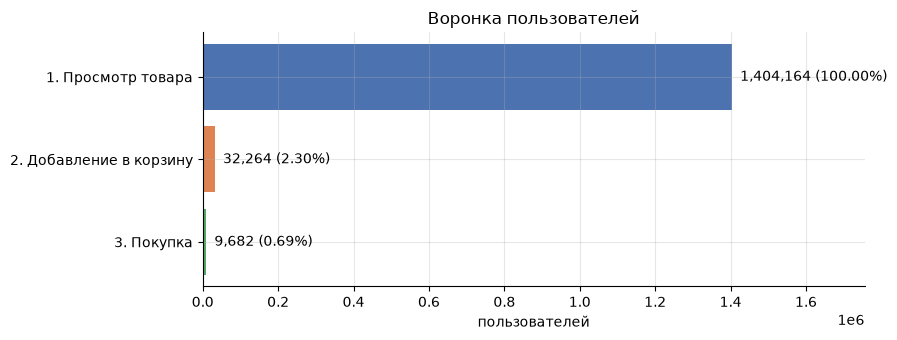

In [18]:
funnel = q("""
SELECT
  SUM(t_view IS NOT NULL)                                                                   AS step1_view,
  SUM(t_view IS NOT NULL AND t_cart IS NOT NULL AND t_cart >= t_view)                       AS step2_cart,
  SUM(t_view IS NOT NULL AND t_cart IS NOT NULL AND t_cart >= t_view
      AND t_buy IS NOT NULL AND t_buy >= t_cart)                                            AS step3_buy,
  SUM(t_buy IS NOT NULL AND (t_cart IS NULL OR t_buy < t_cart))                             AS buy_without_cart_first,
  SUM(t_view IS NULL AND (t_cart IS NOT NULL OR t_buy IS NOT NULL))                         AS active_without_view
FROM mart_user
""").iloc[0]

s1, s2, s3 = int(funnel.step1_view), int(funnel.step2_cart), int(funnel.step3_buy)
funnel_tbl = pd.DataFrame({
    "Шаг": ["1. Просмотр товара", "2. Добавление в корзину", "3. Покупка"],
    "Пользователей": [s1, s2, s3],
    "Конверсия от предыдущего шага, %": [100.0, 100 * s2 / s1, 100 * s3 / s2],
    "Конверсия от шага 1, %": [100.0, 100 * s2 / s1, 100 * s3 / s1],
})
display(funnel_tbl)
print(f"Купили, минуя шаг «корзина» (покупка раньше корзины или без неё): {int(funnel.buy_without_cart_first):,}")
print(f"Были корзина/покупка без единого просмотра: {int(funnel.active_without_view):,}")

fig, ax = plt.subplots(figsize=(9, 3.5))
labels = funnel_tbl["Шаг"][::-1]
vals = funnel_tbl["Пользователей"][::-1]
ax.barh(labels, vals, color=["#55A868", "#DD8452", "#4C72B0"])
for i, (v, pct) in enumerate(zip(vals, funnel_tbl["Конверсия от шага 1, %"][::-1])):
    ax.text(v, i, f"  {v:,} ({pct:.2f}%)", va="center")
ax.set_xlim(0, max(vals) * 1.25); ax.set_title("Воронка пользователей"); ax.set_xlabel("пользователей")
plt.tight_layout(); plt.show()

**Как читать воронку.** Падение на каждом шаге рассчитано относительно предыдущего шага. Отдельно считаются пользователи, которые купили, минуя корзину: их доля показывает, насколько воронка «просмотр → корзина → покупка» вообще описывает реальное поведение, и где в логировании могут быть пробелы (например, покупка в один клик не создаёт события `addtocart`).

### 5.2 Воронка по когортам (месяц первого просмотра)

Когорты более поздних месяцев имели меньше времени на конверсию (данные обрываются в конце периода), поэтому сравнивать надо осторожно.

,cohort,viewers,carted,bought,"view→cart, %","cart→buy, %","view→buy, %"
0,2015-05,306906,7848,2483,2.5571,31.6386,0.8090
1,2015-06,298611,7578,2303,2.5377,30.3906,0.7712
2,2015-07,354956,7663,2286,2.1589,29.8317,0.6440
3,2015-08,287463,6200,1776,2.1568,28.6452,0.6178
4,2015-09,156228,2975,834,1.9043,28.0336,0.5338


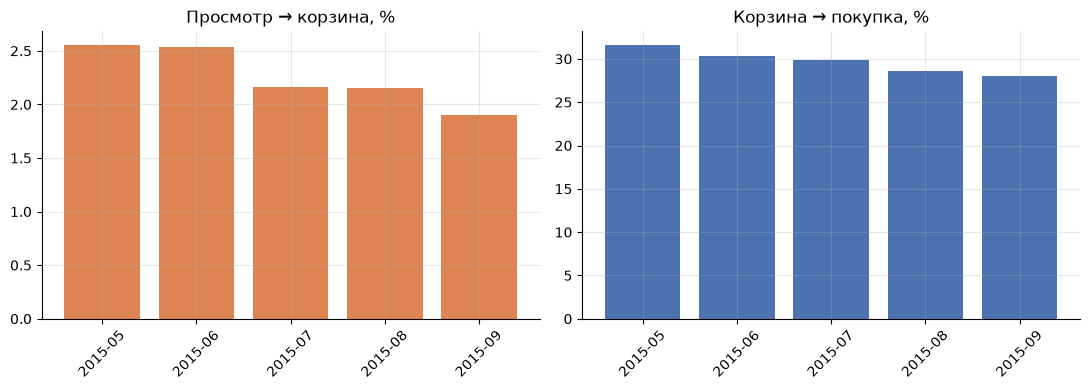

In [19]:
cohorts = q("""
SELECT substr(d_view, 1, 7) AS cohort,
       COUNT(*) AS viewers,
       SUM(t_cart IS NOT NULL AND t_cart >= t_view) AS carted,
       SUM(t_cart IS NOT NULL AND t_cart >= t_view AND t_buy IS NOT NULL AND t_buy >= t_cart) AS bought
FROM mart_user WHERE t_view IS NOT NULL
GROUP BY cohort ORDER BY cohort
""")
cohorts["view→cart, %"] = 100 * cohorts["carted"] / cohorts["viewers"]
cohorts["cart→buy, %"] = 100 * cohorts["bought"] / cohorts["carted"].replace(0, np.nan)
cohorts["view→buy, %"] = 100 * cohorts["bought"] / cohorts["viewers"]
display(cohorts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(cohorts["cohort"], cohorts["view→cart, %"], color="#DD8452"); ax[0].set_title("Просмотр → корзина, %")
ax[1].bar(cohorts["cohort"], cohorts["cart→buy, %"], color="#4C72B0"); ax[1].set_title("Корзина → покупка, %")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 5.3 Воронка по сессиям

Здесь шаги считаются внутри одной сессии: была ли в сессии корзина и покупка.

In [20]:
sess = q("""
SELECT COUNT(*)                                                    AS sessions,
       SUM(views > 0)                                              AS with_view,
       SUM(views > 0 AND carts > 0)                                AS with_cart,
       SUM(views > 0 AND carts > 0 AND purchases > 0)              AS with_buy,
       SUM(events = 1)                                             AS single_event
FROM mart_session
""").iloc[0]
print(f"Сессий всего: {int(sess.sessions):,}; из них с одним событием: {int(sess.single_event):,} ({100 * sess.single_event / sess.sessions:.1f}%)")
sess_tbl = pd.DataFrame({
    "Шаг": ["Сессии с просмотром", "…с добавлением в корзину", "…с покупкой"],
    "Сессий": [int(sess.with_view), int(sess.with_cart), int(sess.with_buy)],
})
sess_tbl["Конверсия от предыдущего шага, %"] = [100.0, 100 * sess.with_cart / sess.with_view, 100 * sess.with_buy / max(sess.with_cart, 1)]
sess_tbl["Конверсия от шага 1, %"] = 100 * sess_tbl["Сессий"] / sess.with_view
sess_tbl

Сессий всего: 1,759,613; из них с одним событием: 1,378,217 (78.3%)


,Шаг,Сессий,"Конверсия от предыдущего шага, %","Конверсия от шага 1, %"
0,Сессии с просмотром,1753719,100.0000,100.0000
1,…с добавлением в корзину,38710,2.2073,2.2073
2,…с покупкой,11143,28.7858,0.6354


### 5.4 Время между шагами

Сколько времени проходит от первого просмотра до корзины и от корзины до покупки.

,"просмотр → корзина, мин","корзина → покупка, мин"
p25,0.9000,3.0000
медиана,3.7000,5.8000
p75,36.4000,16.0000
p90,"5,730.4000",101.9000


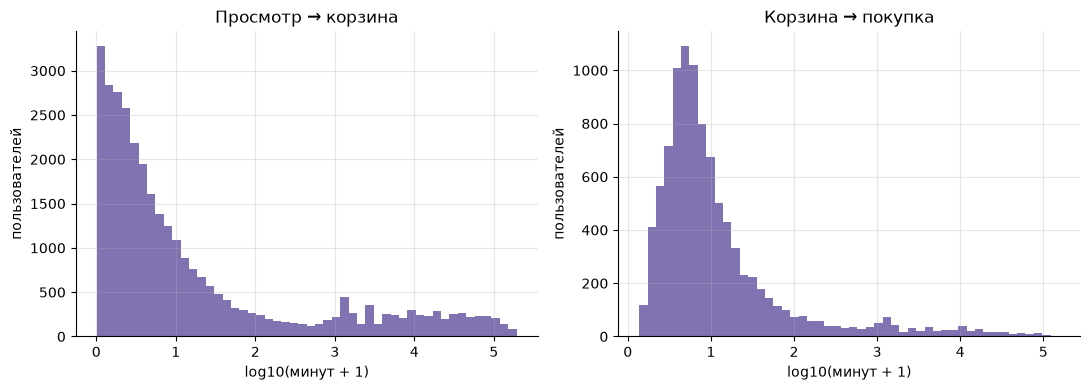

In [21]:
tm = q("""
SELECT t_view, t_cart, t_buy FROM mart_user
WHERE t_view IS NOT NULL AND t_cart IS NOT NULL AND t_cart >= t_view
""")
tm["view_to_cart_min"] = (tm["t_cart"] - tm["t_view"]) / 60_000
bought = tm[tm["t_buy"].notna() & (tm["t_buy"] >= tm["t_cart"])].copy()
bought["cart_to_buy_min"] = (bought["t_buy"] - bought["t_cart"]) / 60_000

def pct(s):
    return s.quantile([.25, .5, .75, .9]).round(1).rename({0.25: "p25", 0.5: "медиана", 0.75: "p75", 0.9: "p90"})

time_tbl = pd.DataFrame({"просмотр → корзина, мин": pct(tm["view_to_cart_min"]),
                         "корзина → покупка, мин": pct(bought["cart_to_buy_min"])})
display(time_tbl)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, s, title in zip(ax, [tm["view_to_cart_min"], bought["cart_to_buy_min"]], ["Просмотр → корзина", "Корзина → покупка"]):
    a.hist(np.log10(s.clip(lower=0.01) + 1), bins=50, color="#8172B2")
    a.set_title(title); a.set_xlabel("log10(минут + 1)"); a.set_ylabel("пользователей")
plt.tight_layout(); plt.show()

### 5.5 День недели и время суток

Метки времени в данных в UTC, часовой пояс магазина неизвестен, поэтому часы указаны в UTC.

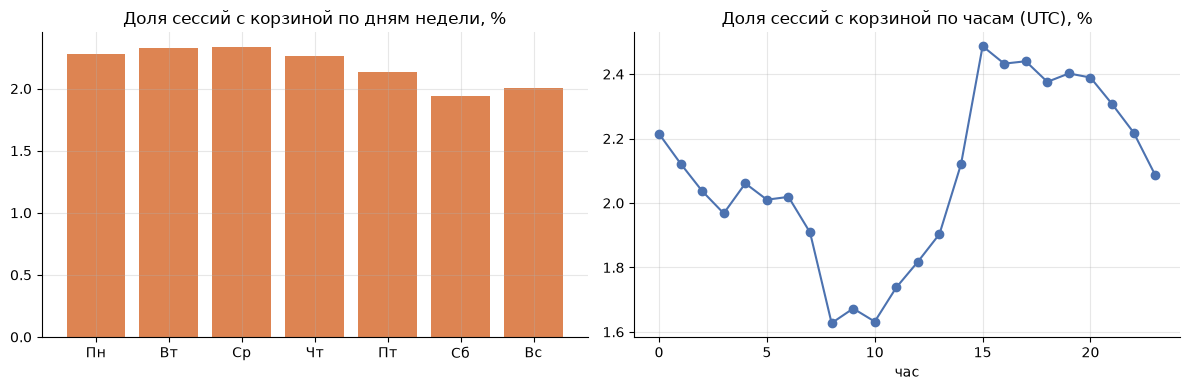

,день,sessions,"сессия → корзина, %","сессия → покупка, %"
0,Пн,278937,2.2754,0.6998
1,Вт,282878,2.3254,0.7197
2,Ср,273107,2.3364,0.7371
3,Чт,265968,2.2593,0.6452
4,Пт,243633,2.1307,0.5828
5,Сб,198758,1.9441,0.4629
6,Вс,216332,2.0062,0.5020


In [22]:
by_dow = q("""
SELECT CAST(strftime('%w', start_ts / 1000, 'unixepoch') AS INTEGER) AS dow,
       COUNT(*) AS sessions,
       SUM(views > 0 AND carts > 0) AS with_cart,
       SUM(views > 0 AND carts > 0 AND purchases > 0) AS with_buy
FROM mart_session GROUP BY dow ORDER BY dow
""")
by_dow["день"] = by_dow["dow"].map({0: "Вс", 1: "Пн", 2: "Вт", 3: "Ср", 4: "Чт", 5: "Пт", 6: "Сб"})
by_dow["сессия → корзина, %"] = 100 * by_dow["with_cart"] / by_dow["sessions"]
by_dow["сессия → покупка, %"] = 100 * by_dow["with_buy"] / by_dow["sessions"]

by_hour = q("""
SELECT CAST(strftime('%H', start_ts / 1000, 'unixepoch') AS INTEGER) AS hour,
       COUNT(*) AS sessions,
       SUM(views > 0 AND carts > 0) AS with_cart,
       SUM(views > 0 AND carts > 0 AND purchases > 0) AS with_buy
FROM mart_session GROUP BY hour ORDER BY hour
""")
by_hour["сессия → корзина, %"] = 100 * by_hour["with_cart"] / by_hour["sessions"]

order = [1, 2, 3, 4, 5, 6, 0]
by_dow = by_dow.set_index("dow").loc[order].reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(by_dow["день"], by_dow["сессия → корзина, %"], color="#DD8452"); ax[0].set_title("Доля сессий с корзиной по дням недели, %")
ax[1].plot(by_hour["hour"], by_hour["сессия → корзина, %"], marker="o", color="#4C72B0"); ax[1].set_title("Доля сессий с корзиной по часам (UTC), %")
ax[1].set_xlabel("час")
plt.tight_layout(); plt.show()
by_dow[["день", "sessions", "сессия → корзина, %", "сессия → покупка, %"]]

### 5.6 Отказ от корзины и «проблемные» товары

Какая доля пользователей добавила товар в корзину, но не купила его, и какие товары чаще всего остаются в корзине.

In [23]:
aband = q("""
SELECT COUNT(*) AS cart_users,
       SUM(t_buy IS NOT NULL AND t_buy >= t_cart) AS bought_after_cart
FROM mart_user WHERE t_cart IS NOT NULL
""").iloc[0]
print(f"Пользователей с корзиной: {int(aband.cart_users):,}; купили после корзины: {int(aband.bought_after_cart):,}; "
      f"отказ от корзины: {100 * (1 - aband.bought_after_cart / aband.cart_users):.1f}%")

items_tbl = q(f"""
WITH carts AS (
    SELECT visitor_id, item_id, MIN(ts_ms) AS t_cart
    FROM events WHERE event = 'addtocart' GROUP BY visitor_id, item_id
)
SELECT c.item_id,
       COUNT(*) AS cart_users,
       SUM(EXISTS (SELECT 1 FROM events t WHERE t.visitor_id = c.visitor_id AND t.item_id = c.item_id
                   AND t.event = 'transaction' AND t.ts_ms >= c.t_cart)) AS bought
FROM carts c
GROUP BY c.item_id
HAVING COUNT(*) >= {MIN_CARTS_ITEM}
""")
if len(items_tbl):
    items_tbl["cart→buy, %"] = 100 * items_tbl["bought"] / items_tbl["cart_users"]
    print(f"\nТовары с ≥ {MIN_CARTS_ITEM} добавлениями в корзину: {len(items_tbl)}. Наименьшая конверсия корзина → покупка:")
    display(items_tbl.sort_values("cart→buy, %").head(10))
else:
    print(f"Нет товаров с ≥ {MIN_CARTS_ITEM} добавлениями в корзину: уменьши MIN_CARTS_ITEM.")

Пользователей с корзиной: 37,714; купили после корзины: 10,447; отказ от корзины: 72.3%

Товары с ≥ 20 добавлениями в корзину: 169. Наименьшая конверсия корзина → покупка:


,item_id,cart_users,bought,"cart→buy, %"
85,250643,32,1,3.1250
120,354233,21,1,4.7619
1,3146,20,1,5.0000
48,149230,26,2,7.6923
92,279457,62,5,8.0645
60,181045,24,2,8.3333
145,403576,22,2,9.0909
161,451806,21,2,9.5238
110,321905,20,2,10.0000
143,398579,20,2,10.0000


## Шаг 6. Эд-хок запросы

Примеры быстрых аналитических вопросов, которые прилетают от продуктовых команд, и ответы на них одним SQL-запросом.

**Запрос 1. Топ-10 товаров по просмотрам и их конверсия в корзину.**

In [24]:
q("""
SELECT item_id,
       SUM(event = 'view')       AS views,
       SUM(event = 'addtocart')  AS carts,
       SUM(event = 'transaction') AS purchases,
       ROUND(100.0 * SUM(event = 'addtocart') / SUM(event = 'view'), 2) AS view_to_cart_pct
FROM events
GROUP BY item_id
ORDER BY views DESC
LIMIT 10
""")

,item_id,views,carts,purchases,view_to_cart_pct
0,187946,3410,2,0,0.0600
1,461686,2538,304,133,11.9800
2,5411,2322,9,0,0.3900
3,370653,1854,0,0,0.0000
4,219512,1740,48,12,2.7600
5,298009,1642,0,0,0.0000
6,96924,1633,0,0,0.0000
7,309778,1565,48,15,3.0700
8,257040,1531,89,27,5.8100
9,384302,1524,65,15,4.2700


**Запрос 2. Сколько покупателей совершили повторные покупки (2+ разных заказа)?**

In [25]:
q("""
SELECT COUNT(*)                                             AS buyers,
       SUM(orders >= 2)                                     AS repeat_buyers,
       ROUND(100.0 * SUM(orders >= 2) / COUNT(*), 2)        AS repeat_share_pct
FROM mart_user WHERE orders >= 1
""")

,buyers,repeat_buyers,repeat_share_pct
0,11719,1063,9.0700


**Запрос 3. Сколько «одноразовых» посетителей (1 сессия, 1 событие) и как их доля менялась по месяцам?**

In [26]:
q("""
SELECT substr(first_date, 1, 7) AS month,
       COUNT(*) AS new_visitors,
       SUM(sessions = 1 AND views + carts + purchases = 1) AS one_event_visitors,
       ROUND(100.0 * SUM(sessions = 1 AND views + carts + purchases = 1) / COUNT(*), 1) AS one_event_pct
FROM mart_user
GROUP BY month ORDER BY month
""")

,month,new_visitors,one_event_visitors,one_event_pct
0,2015-05,307565,206467,67.1000
1,2015-06,299188,205632,68.7000
2,2015-07,355761,258153,72.6000
3,2015-08,288327,213049,73.9000
4,2015-09,156724,118290,75.5000


## Шаг 7. Рефакторинг и оптимизация SQL

Типичная задача: дневная воронка по уникальным пользователям (`viewers`, `cart_users`, `buyers`). Сравним три версии запроса на одном и том же окне данных:

- **V0 (до).** Коррелированные подзапросы на каждый день и метрику, функция `substr()` над столбцом в фильтре (индекс использовать нельзя), каждый подзапрос заново сканирует всю таблицу.
- **V1.** Один проход с условной агрегацией (`GROUP BY` + `CASE WHEN`), но без индекса.
- **V2.** Тот же запрос + составной индекс по `(event_date, event, visitor_id)`.

Корректность проверяем: результаты всех версий должны совпасть.

In [27]:
dates = q("SELECT date FROM mart_daily ORDER BY date")["date"].tolist()
d_from, d_to = dates[0], dates[min(OPT_DAYS, len(dates)) - 1]
print(f"Окно сравнения: {d_from} .. {d_to}")

V0 = """
SELECT d.date,
       (SELECT COUNT(DISTINCT visitor_id) FROM events WHERE substr(event_dt, 1, 10) = d.date AND event = 'view')        AS viewers,
       (SELECT COUNT(DISTINCT visitor_id) FROM events WHERE substr(event_dt, 1, 10) = d.date AND event = 'addtocart')   AS cart_users,
       (SELECT COUNT(DISTINCT visitor_id) FROM events WHERE substr(event_dt, 1, 10) = d.date AND event = 'transaction') AS buyers
FROM (SELECT DISTINCT substr(event_dt, 1, 10) AS date FROM events
      WHERE substr(event_dt, 1, 10) BETWEEN ? AND ?) d
ORDER BY d.date
"""

V1 = """
SELECT event_date AS date,
       COUNT(DISTINCT CASE WHEN event = 'view'        THEN visitor_id END) AS viewers,
       COUNT(DISTINCT CASE WHEN event = 'addtocart'   THEN visitor_id END) AS cart_users,
       COUNT(DISTINCT CASE WHEN event = 'transaction' THEN visitor_id END) AS buyers
FROM events
WHERE event_date BETWEEN ? AND ?
GROUP BY event_date
ORDER BY event_date
"""

print("План выполнения V0:")
for r in conn.execute("EXPLAIN QUERY PLAN " + V0, (d_from, d_to)).fetchall():
    print("  ", r[3])

r0, t0_ = timed(lambda: q(V0, (d_from, d_to)))
r1, t1_ = timed(lambda: q(V1, (d_from, d_to)), repeat=3)

run("DROP INDEX IF EXISTS idx_events_date_event_visitor")
t_idx0 = time.perf_counter()
run("CREATE INDEX idx_events_date_event_visitor ON events(event_date, event, visitor_id)")
t_idx = time.perf_counter() - t_idx0
r2, t2_ = timed(lambda: q(V1, (d_from, d_to)), repeat=3)

print("\nПлан выполнения V2 (V1 + индекс):")
for r in conn.execute("EXPLAIN QUERY PLAN " + V1, (d_from, d_to)).fetchall():
    print("  ", r[3])

assert r0.reset_index(drop=True).equals(r1.reset_index(drop=True)) and r1.equals(r2), "Результаты версий не совпали!"
print("\n✅ Результаты всех версий совпадают")

opt = pd.DataFrame({
    "Версия": ["V0: коррелированные подзапросы, substr(), без индекса", "V1: один проход, условная агрегация", "V2: V1 + составной индекс"],
    "Время, с": [t0_, t1_, t2_],
})
opt["Ускорение к V0, ×"] = t0_ / opt["Время, с"]
display(opt)
print(f"Построение индекса заняло {t_idx:.1f} с (разовая стоимость)")

Окно сравнения: 2015-05-03 .. 2015-05-05
План выполнения V0:
   CO-ROUTINE d
   SCAN events
   USE TEMP B-TREE FOR DISTINCT
   SCAN d
   CORRELATED SCALAR SUBQUERY 1
   SCAN events USING INDEX idx_events_visitor_ts
   CORRELATED SCALAR SUBQUERY 2
   SCAN events USING INDEX idx_events_visitor_ts
   CORRELATED SCALAR SUBQUERY 3
   SCAN events USING INDEX idx_events_visitor_ts
   USE TEMP B-TREE FOR ORDER BY

План выполнения V2 (V1 + индекс):
   SEARCH events USING COVERING INDEX idx_events_date_event_visitor (event_date>? AND event_date<?)
   USE TEMP B-TREE FOR count(DISTINCT)
   USE TEMP B-TREE FOR count(DISTINCT)
   USE TEMP B-TREE FOR count(DISTINCT)

✅ Результаты всех версий совпадают


,Версия,"Время, с","Ускорение к V0, ×"
0,"V0: коррелированные подзапросы, substr(), без ...",19.6029,1.0000
1,"V1: один проход, условная агрегация",0.1424,137.6730
2,V2: V1 + составной индекс,0.0131,"1,500.1726"


Построение индекса заняло 1.7 с (разовая стоимость)


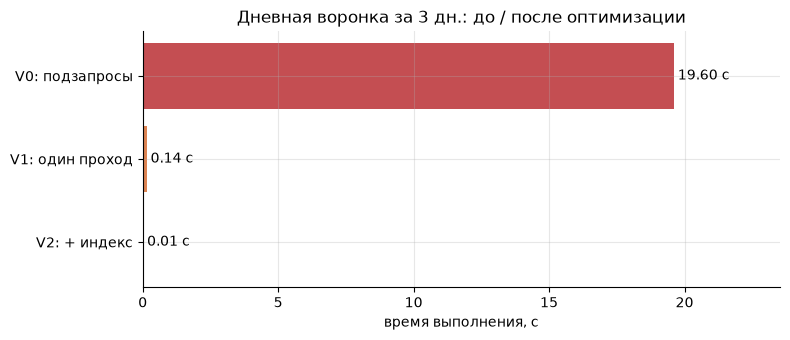

Оптимизированный запрос V2 на всём периоде (139 дней): 0.66 с


In [28]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(["V2: + индекс", "V1: один проход", "V0: подзапросы"], [t2_, t1_, t0_], color=["#55A868", "#DD8452", "#C44E52"])
for i, v in enumerate([t2_, t1_, t0_]):
    ax.text(v, i, f" {v:.2f} с", va="center")
ax.set_xlabel("время выполнения, с"); ax.set_title(f"Дневная воронка за {OPT_DAYS} дн.: до / после оптимизации")
ax.set_xlim(0, t0_ * 1.2)
plt.tight_layout(); plt.show()

full, t_full = timed(lambda: q(V1, (dates[0], dates[-1])))
print(f"Оптимизированный запрос V2 на всём периоде ({len(dates)} дней): {t_full:.2f} с")

**Что дал рефакторинг:**
1. Убраны коррелированные подзапросы: вместо `3 × N дней` полных сканирований таблицы один проход.
2. Фильтр по готовому столбцу `event_date` вместо `substr(event_dt, 1, 10)`: функция над столбцом делает индекс бесполезным.
3. Составной индекс `(event_date, event, visitor_id)` позволяет читать только нужные дни и считать `COUNT(DISTINCT visitor_id)` по индексу.
4. Тяжёлые агрегаты вынесены в витрину `mart_daily`: дашборд читает готовую маленькую таблицу, а не сырые события.

## Шаг 8. Дашборд с фильтрами

Интерактивный дашборд на `ipywidgets`: фильтры по периоду (по дате первого просмотра), сегменту пользователей и детализации тренда. Данные берутся из витрин `mart_user` и `mart_daily`, а не из сырых событий.

> Виджеты работают при запуске ноутбука в Jupyter. GitHub интерактивные виджеты не отображает, поэтому ниже отдельно показан статический снимок с параметрами по умолчанию, а скриншоты сохранены в `img/`.

**Как это переносится в Redash:** каждая витрина становится запросом (`SELECT ... FROM mart_daily`), параметры `{{ date_from }}`, `{{ date_to }}` и `{{ segment }}` заменяют виджеты, а воронка и тренд оформляются как визуализации (Funnel, Line chart) на одном дашборде.

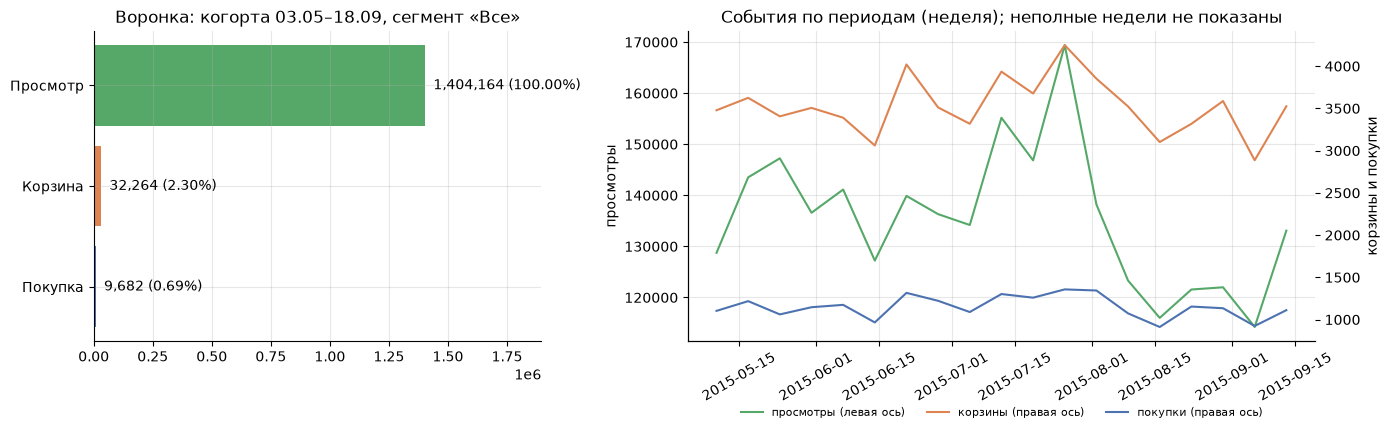

In [29]:
import ipywidgets as widgets
from IPython.display import display

daily = q("SELECT * FROM mart_daily ORDER BY date")
daily["date"] = pd.to_datetime(daily["date"])
users = q("SELECT visitor_id, d_view, t_view, t_cart, t_buy, sessions FROM mart_user WHERE t_view IS NOT NULL")
users["d_view"] = pd.to_datetime(users["d_view"])


def draw_dashboard(period, granularity="День", segment="Все", save_as=None):
    start, end = pd.Timestamp(period[0]), pd.Timestamp(period[1])
    u = users[(users["d_view"] >= start) & (users["d_view"] <= end)]
    if segment == "1 сессия":
        u = u[u["sessions"] == 1]
    elif segment == "2+ сессий":
        u = u[u["sessions"] >= 2]

    s1 = len(u)
    cart = u["t_cart"].notna() & (u["t_cart"] >= u["t_view"])
    s2 = int(cart.sum())
    s3 = int((cart & u["t_buy"].notna() & (u["t_buy"] >= u["t_cart"])).sum())

    d = daily[(daily["date"] >= start) & (daily["date"] <= end)].set_index("date")
    rule = "D" if granularity == "День" else "W"
    tr = d[["views", "carts", "purchases"]].resample(rule).sum()
    if rule == "W":   # неполные недели по краям периода искажают тренд, поэтому исключаем их
        tr = tr[d["views"].resample(rule).count() >= 7]

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
    vals = [s3, s2, s1]
    ax[0].barh(["Покупка", "Корзина", "Просмотр"], vals, color=["#4C72B0", "#DD8452", "#55A868"])
    for i, v in enumerate(vals):
        pct = 100 * v / s1 if s1 else 0
        ax[0].text(v, i, f"  {v:,} ({pct:.2f}%)", va="center")
    ax[0].set_xlim(0, max(max(vals), 1) * 1.35)
    ax[0].set_title(f"Воронка: когорта {start:%d.%m}–{end:%d.%m}, сегмент «{segment}»")

    ax[1].plot(tr.index, tr["views"], color="#55A868", label="просмотры (левая ось)")
    ax[1].set_ylabel("просмотры")
    ax2 = ax[1].twinx()
    ax2.plot(tr.index, tr["carts"], color="#DD8452", label="корзины (правая ось)")
    ax2.plot(tr.index, tr["purchases"], color="#4C72B0", label="покупки (правая ось)")
    ax2.set_ylabel("корзины и покупки"); ax2.grid(False)
    h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax[1].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8, frameon=False)
    ax[1].tick_params(axis="x", rotation=30)
    ax[1].set_title(f"События по периодам ({granularity.lower()}); неполные недели не показаны" if rule == "W" else "События по дням")
    plt.tight_layout()
    if save_as:
        Path(save_as).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_as, dpi=130, bbox_inches="tight")
    plt.show()


all_dates = list(daily["date"].dt.date)
draw_dashboard((all_dates[0], all_dates[-1]), "Неделя", "Все", save_as="../img/dashboard_default.png")

In [30]:
period = widgets.SelectionRangeSlider(options=all_dates, index=(0, len(all_dates) - 1),
                                      description="Период", layout=widgets.Layout(width="95%"))
gran = widgets.ToggleButtons(options=["День", "Неделя"], value="Неделя", description="Детализация")
seg = widgets.Dropdown(options=["Все", "1 сессия", "2+ сессий"], value="Все", description="Сегмент")

ui = widgets.VBox([period, widgets.HBox([gran, seg])])
out = widgets.interactive_output(lambda period, granularity, segment: draw_dashboard(period, granularity, segment),
                                 {"period": period, "granularity": gran, "segment": seg})
display(ui, out)

Output()

## Шаг 9. Итоги

In [31]:
removed = N_RAW - n_events
print("=== Ключевые результаты ===")
print(f"Загружено событий: {N_RAW:,}; после очистки и удаления ботов: {n_events:,} (удалено {100 * removed / N_RAW:.2f}%)")
print(f"Ботов исключено: {n_bots}; события ботов: {bot_events:,}")
print(f"Покупок без предшествующей корзины: {100 * pwc / max(pur, 1):.1f}%; корзин без просмотра: {100 * cwv / max(car, 1):.1f}%")
print(f"\nВоронка пользователей: просмотр {s1:,} → корзина {s2:,} ({100 * s2 / s1:.2f}%) → покупка {s3:,} ({100 * s3 / s2:.2f}% от корзины; {100 * s3 / s1:.3f}% от просмотра)")
print(f"Отказ от корзины: {100 * (1 - aband.bought_after_cart / aband.cart_users):.1f}%")
print(f"Время просмотр → корзина (медиана): {time_tbl.loc['медиана', 'просмотр → корзина, мин']} мин; "
      f"корзина → покупка (медиана): {time_tbl.loc['медиана', 'корзина → покупка, мин']} мин")
print(f"\nОптимизация дневной воронки: {t0_:.2f} с → {t2_:.2f} с (ускорение ×{t0_ / t2_:.0f})")
if USING_SYNTHETIC:
    print("\n⚠️ Это результат на СИНТЕТИЧЕСКИХ данных. Для README и резюме используй только результаты на реальном датасете.")

=== Ключевые результаты ===
Загружено событий: 2,756,101; после очистки и удаления ботов: 2,741,333 (удалено 0.54%)
Ботов исключено: 15; события ботов: 14,308
Покупок без предшествующей корзины: 10.9%; корзин без просмотра: 27.4%

Воронка пользователей: просмотр 1,404,164 → корзина 32,264 (2.30%) → покупка 9,682 (30.01% от корзины; 0.690% от просмотра)
Отказ от корзины: 72.3%
Время просмотр → корзина (медиана): 3.7 мин; корзина → покупка (медиана): 5.8 мин

Оптимизация дневной воронки: 19.60 с → 0.01 с (ускорение ×1500)


### Выводы

**1. Качество данных.** Датасет оказался чистым по структуре: нет пропусков в ключевых полях, недопустимых типов событий, времени вне периода и покупок без `transactionid`. Из 2 756 101 события удалено 0,54%: 460 точных дублей (0,017%) и 14 308 событий 15 ботов (0,52%). Остальные находки касаются **логики и полноты логирования**, а не мусора в полях:
- **27,4% добавлений в корзину** (18 881 из 68 946) не имеют предшествующего просмотра этого товара. Часть объясняется просмотрами до начала периода сбора (3 мая) или сменой устройства, но масштаб говорит о пробеле в логировании.
- **10,9% покупок** (2 452 из 22 457) совершены без добавления этого товара в корзину: вероятно, покупка в один клик или пропущенные события `addtocart`.
- В данных 75 посетителей с ≥500 событий, из них **60 с покупками**: их оставили (рекордсмен: 7 757 событий и 559 покупок, вероятно, перепродавец или служебный аккаунт). Их вклад в покупки отдельно не оценивался.
- Два последних дня периода неполные: 18 сентября всего 1 528 событий, 17 сентября 10 126 (≈49% медианы 20 619). Скорее всего, это обрыв сбора, а не сбой логирования, но данных для подтверждения нет.

**2. Воронка.** Из 1 404 164 пользователей с просмотром **2,30%** (32 264) добавили товар в корзину и **30,0%** из них (9 682) купили, то есть **0,69%** от просмотревших. Главная потеря на шаге «просмотр → корзина» (97,7%), но ближе всего к деньгам шаг «корзина → покупка»: **отказ от корзины 72,3%** (37 714 пользователей с корзиной, 10 447 купили после неё). Ещё 1 272 пользователя купили в обход корзины, а у 3 401 были корзина или покупка без единого просмотра, то есть воронка из трёх шагов описывает поведение не полностью. В сессиях картина похожа: 2,21% сессий с корзиной, 0,64% с покупкой; **78,3% сессий состоят из одного события**.

**3. Динамика по когортам (месяц первого просмотра).** Конверсия снижается:

| Когорта | просмотр → корзина | корзина → покупка | просмотр → покупка |
|---|---|---|---|
| 2015-05 | 2,56% | 31,6% | 0,81% |
| 2015-06 | 2,54% | 30,4% | 0,77% |
| 2015-07 | 2,16% | 29,8% | 0,64% |
| 2015-08 | 2,16% | 28,6% | 0,62% |
| 2015-09 | 1,90% | 28,0% | 0,53% |

Доля посетителей с одним событием за тот же период выросла с **67,1% до 75,5%**, а в июле на дашборде видно пик просмотров (до ≈170 тыс. в неделю) без роста числа корзин и покупок. Это согласуется с гипотезой, что трафик стал более «поверхностным» (больше случайных заходов), но **источников трафика в данных нет, поэтому причину проверить нельзя**. Оговорка: сентябрьская когорта неполная (данные до 18 сентября), её конверсию в покупку нельзя сравнивать напрямую.

**4. Время и сезонность.** Медиана от первого просмотра до корзины 3,7 минуты (p75 = 36 минут, но p90 ≈ 5 730 минут, то есть около 4 дней: часть пользователей возвращается позже). От корзины до покупки медиана 5,8 минуты, p90 около 102 минут: покупатели решаются быстро: 90% тех, кто купил после корзины, сделали это в течение 1–2 часов. Конверсия сессии в покупку **с понедельника по четверг 0,65–0,74%, в пятницу 0,58%, в выходные 0,46–0,50%** (суббота на 37% ниже среды), при этом и трафик в выходные ниже. По часам доля сессий с корзиной минимальна в 08–10 UTC (≈1,6%) и максимальна около 15 UTC (≈2,5%); часовой пояс магазина неизвестен.

**5. Товары.** Из 169 товаров с ≥20 добавлениями в корзину наименьшая конверсия корзина → покупка у товаров 250643 (1 покупка на 32 корзины), 354233, 3146 и 279457 (5 покупок на 62 корзины). Выборки небольшие, поэтому это **кандидаты для разбора** (цена, наличие, доставка), а не выводы. Отдельная проблема в топе по просмотрам: товары 370653, 298009 и 96924 набрали по 1 500–1 850 просмотров без единой корзины, а товар 187946 (3 410 просмотров) только 2 корзины. Стоит проверить, можно ли их вообще заказать. Повторные покупки делают 9,1% покупателей (1 063 из 11 719).

**6. Оптимизация SQL.** Дневная воронка по уникальным пользователям: исходный запрос с коррелированными подзапросами и `substr()` выполнялся **19,6 с** на трёх днях, версия с одним проходом и условной агрегацией **0,14 с** (×137), с составным индексом **0,013 с** (×1 474); построение индекса заняло 1,6 с. Запрос на всём периоде (139 дней) выполняется за 0,66 с. Результаты всех версий совпадают.

**7. Что бы я сделал дальше.**
- Добавил в логирование `session_id`, событие `checkout_started`, цену, количество и источник трафика.
- Разобрал причины отказа от корзины (72,3%) и предложил A/B-тест: напоминание о товаре в корзине или упрощение оформления. Основная метрика: конверсия корзина → покупка.
- Проверил товары без корзин на доступность и наличие кнопки «в корзину».